# Atropelamentos em São Paulo (2022–2025): pontos críticos com DBSCAN e índice da CET

**Pré-requisito:** rodar antes o notebook `01_limpeza_analise_atropelamentos_sp.ipynb`, que gera
`data/processed/atropelamentos_sp_2022_2025.parquet`.

**Pergunta:** onde estão as concentrações de atropelamentos que deveriam ser tratadas primeiro, e em que
posição fica o piloto do projeto (Av. Celso Garcia / Largo da Concórdia, Brás)?

**De onde vem o método.** Na reunião da Câmara Temática da Mobilidade a Pé (11/03/2026), a CET apresentou um
trabalho feito **à mão** sobre o mapa do Infosiga: 16.390 atropelamentos georreferenciados de 2022–2025,
delimitados em **244 concentrações**. Para cada concentração, a CET mediu a extensão do trecho da via e calculou

$$\text{índice} = \frac{\text{extensão do trecho (m)}}{\text{não fatais} + 3 \times \text{fatais}}$$

O índice dá "metros de via por atropelamento ponderado". **Quanto menor, mais denso e mais prioritário.**
O exemplo citado na reunião: a concentração "Estado 1" tem 86 m, 3 não fatais e 2 fatais, e índice
86 / 9 ≈ 9,6 (um atropelamento ponderado a cada ~10 m).

**O que este notebook faz:** reproduz o método de forma **automática e reprodutível**. O DBSCAN delimita as
concentrações, o índice é calculado do mesmo jeito, o resultado sai num mapa e tudo é gravado no banco
SQLite do projeto.

## 1. Configuração e leitura

In [1]:
from pathlib import Path
import json, base64, sqlite3, unicodedata, datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import folium
import branca.colormap as bcm
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import haversine_distances

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
PROCESSED = ROOT / "data" / "processed"
NOTEBOOKS = ROOT / "src" / "estudo_b_risco_vida"
EVID = ROOT / "docs" / "evidencias" / "estudo_b"
EVID.mkdir(parents=True, exist_ok=True)
DB_PATH = PROCESSED / "seguranca_viaria.db"

R_TERRA = 6_371_000  # raio médio da Terra em metros (o haversine do scikit-learn trabalha em radianos)

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

def salvar(fig, nome):
    """Salva a figura em docs/evidencias/estudo_b/ (para o PDF e o vídeo)."""
    fig.savefig(EVID / nome, dpi=150, bbox_inches="tight", facecolor="white")

atrop = pd.read_parquet(PROCESSED / "atropelamentos_sp_2022_2025.parquet")
geo = atrop[atrop["coord_valida"]].copy().reset_index(drop=True)
print(f"atropelamentos no recorte: {len(atrop):,} | com coordenada válida: {len(geo):,} "
      f"({len(geo) / len(atrop):.1%}) | fatais com coordenada: {geo['fatal'].sum():,}")

atropelamentos no recorte: 16,245 | com coordenada válida: 15,595 (96.0%) | fatais com coordenada: 1,240


**Por que só `coord_valida`:** o DBSCAN agrupa pela distância entre os pontos, então um atropelamento sem
coordenada (ou com coordenada fora da cidade, ver notebook 01, seção 2.3) não tem onde entrar. Esses casos
**não são apagados**: continuam na tabela `sinistros` do banco, com `cluster_id` nulo.

A base da CET tinha 16.390 registros georreferenciados e a nossa tem ~15,6 mil. A diferença deve vir do
recorte (aqui ficam de fora as `NOTIFICACAO`, os registros sem vítima confirmada) e da data de extração dos
dados (19/10/2026).

**Padronização de nomes só para agrupar:** o campo `logradouro_pad` ainda mistura grafias com e sem acento
(`LARGO DA CONCORDIA` / `LARGO DA CONCÓRDIA`). Para escolher a via principal de cada grupo, tiramos os
acentos numa coluna auxiliar (`via_norm`), sem alterar a base.

In [2]:
def sem_acento(s: pd.Series) -> pd.Series:
    return s.map(lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode()
                 if isinstance(x, str) else x)

geo["via_norm"] = sem_acento(geo["logradouro_pad"])
X = np.radians(geo[["latitude", "longitude"]].to_numpy())
PESO = np.where(geo["fatal"], 3, 1)  # fatal vale 3, igual ao critério da CET
print(f"soma dos pesos: {PESO.sum():,} (= {(~geo['fatal']).sum():,} não fatais + 3 × {geo['fatal'].sum():,} fatais)")

soma dos pesos: 18,075 (= 14,355 não fatais + 3 × 1,240 fatais)


## 2. DBSCAN

**Como funciona aqui.** O DBSCAN marca um ponto como "núcleo" quando, num raio `eps` em volta dele, a soma
dos pesos chega a `min_samples`. Núcleos vizinhos se juntam num grupo, e os pontos isolados ficam como
**ruído** (`label = -1`). Escolhemos o DBSCAN por três motivos:

- **Não precisa dizer quantos grupos existem**, ao contrário do k-means. A CET também não partiu de um número:
  as 244 concentrações foram o resultado da delimitação.
- **Deixa os casos isolados de fora.** Um atropelamento solto numa avenida não vira "ponto crítico", e foi
  isso que a CET fez à mão ("tem um atropelamento isolado aqui e outro ali").
- **Aceita peso por ponto** (`sample_weight`). Com fatal = 3, o limiar `min_samples` passa a valer em
  **atropelamentos ponderados**, a mesma unidade do índice da CET. Assim, 3 fatais próximos pesam tanto quanto
  9 não fatais.

**Distância:** `metric="haversine"` com coordenadas em radianos dá a distância real sobre a esfera.
`eps` em metros vira radianos dividindo pelo raio da Terra (`eps = metros / 6.371.000`). O `ball_tree` é a
estrutura de busca que aceita essa métrica.

In [3]:
def rodar_dbscan(eps_m: float, min_samples: int) -> np.ndarray:
    modelo = DBSCAN(eps=eps_m / R_TERRA, min_samples=min_samples, metric="haversine", algorithm="ball_tree")
    return modelo.fit_predict(X, sample_weight=PESO)

def extensao_m(lat: np.ndarray, lon: np.ndarray) -> float:
    """Maior distância haversine (m) entre dois pontos do grupo, ou seja, o 'diâmetro' do grupo."""
    if len(lat) < 2:
        return 0.0
    return float(haversine_distances(np.radians(np.c_[lat, lon])).max() * R_TERRA)

### 2.1 Escolha dos hiperparâmetros

Testamos `eps` ∈ {50, 75, 100, 150} m e `min_samples` ∈ {8, 10, 15} (em peso). Além do número de grupos, do
% de pontos agrupados e do tamanho mediano, a tabela mostra **o maior grupo** e **quantos grupos passam de
1 km de extensão**. Essas duas colunas revelam o principal risco do DBSCAN, o **encadeamento**: com `eps`
grande, pontos vizinhos vão se ligando um ao outro e trechos diferentes viram um grupo só.

In [4]:
EPS_GRADE, MS_GRADE = [50, 75, 100, 150], [8, 10, 15]
linhas = []
for eps_m in EPS_GRADE:
    for ms in MS_GRADE:
        lab = rodar_dbscan(eps_m, ms)
        tam = pd.Series(lab[lab >= 0]).value_counts()
        ext = [extensao_m(geo.loc[lab == k, "latitude"].to_numpy(), geo.loc[lab == k, "longitude"].to_numpy())
               for k in tam.index]
        linhas.append({"eps_m": eps_m, "min_samples": ms, "grupos": len(tam),
                       "% pontos agrupados": round((lab >= 0).mean() * 100, 1),
                       "tamanho mediano": tam.median(), "maior grupo (pontos)": tam.max(),
                       "extensão máx. (m)": round(max(ext)), "grupos > 1 km": int(np.sum(np.array(ext) > 1000)),
                       "distância de 244": abs(len(tam) - 244)})
grade = pd.DataFrame(linhas)
grade

,eps_m,min_samples,grupos,% pontos agrupados,tamanho mediano,maior grupo (pontos),extensão máx. (m),grupos > 1 km,distância de 244
0,50,8,94,5.5,7.5,53,233,0,150
1,50,10,49,3.4,9.0,53,188,0,195
2,50,15,11,1.3,15.0,53,89,0,233
3,75,8,181,11.2,8.0,57,422,0,63
4,75,10,86,6.5,10.0,57,311,0,158
5,75,15,26,2.7,15.0,57,237,0,218
6,100,8,290,20.3,9.0,72,730,0,46
7,100,10,149,12.5,10.0,68,730,0,95
8,100,15,41,4.8,15.0,60,393,0,203
9,150,8,394,37.1,9.0,761,3475,6,150


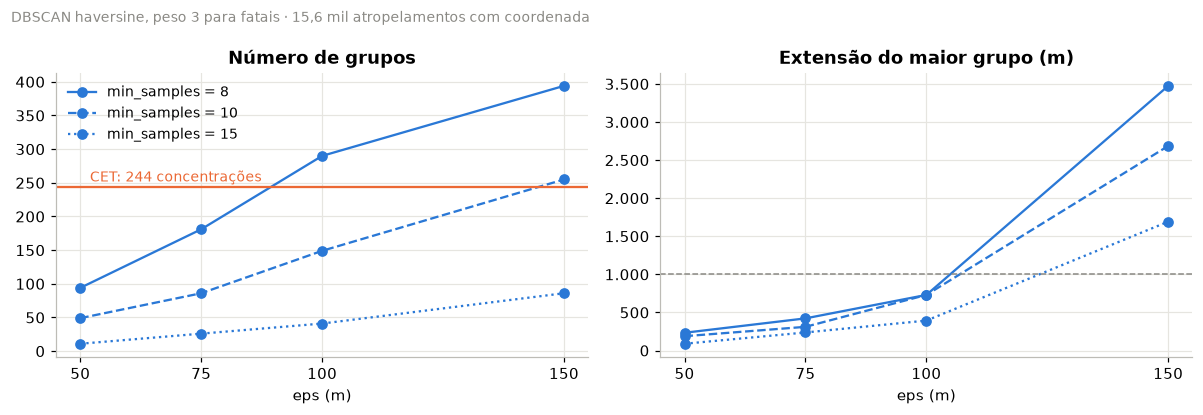

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
estilos = {8: "-", 10: "--", 15: ":"}
for ms, d in grade.groupby("min_samples"):
    axes[0].plot(d["eps_m"], d["grupos"], color=AZUL, ls=estilos[ms], marker="o", label=f"min_samples = {ms}")
    axes[1].plot(d["eps_m"], d["extensão máx. (m)"], color=AZUL, ls=estilos[ms], marker="o")
axes[0].axhline(244, color=LARANJA, lw=1.5)
axes[0].text(52, 252, "CET: 244 concentrações", color=LARANJA, fontsize=9)
axes[0].set_title("Número de grupos")
axes[0].legend(frameon=False, fontsize=9)
axes[1].axhline(1000, color=CINZA, lw=1, ls="--")
axes[1].set_title("Extensão do maior grupo (m)")
for ax in axes:
    ax.set_xticks(EPS_GRADE); ax.set_xlabel("eps (m)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
fig.suptitle("DBSCAN haversine, peso 3 para fatais · 15,6 mil atropelamentos com coordenada", x=0.01,
             ha="left", fontsize=9, color=CINZA)
fig.tight_layout()
salvar(fig, "03_grade_hiperparametros.png")
plt.show()

**Leitura e escolha:** `EPS_M = 100` e `MIN_SAMPLES = 8`.

- A combinação **mais próxima de 244** é `eps = 150 m, min_samples = 10` (255 grupos), mas ela **junta trechos
  claramente diferentes**. O maior grupo tem 519 pontos e ~2,4 km e reúne praticamente todo o Centro
  (Tiradentes, Prestes Maia, 25 de Março: 156 vias diferentes). Outro grupo, de 2,7 km, funde Av. Rangel Pestana,
  Largo da Concórdia e Av. Celso Garcia num único "ponto". Uma concentração de 2,7 km não aponta lugar de
  intervenção. Com `eps = 150 m`, as três combinações têm grupos acima de 1 km: o encadeamento começa
  entre 100 e 150 m (gráfico da direita).
- Entre as combinações **sem encadeamento** (nenhum grupo > 1 km), `100 m / 8` é a mais próxima de 244
  (290 grupos, 46 de distância). O maior grupo tem ~730 m, coerente com um trecho de avenida ou um
  cruzamento grande.
- Passar de 244 é esperado. A CET delimitou à mão e pôde juntar núcleos vizinhos da mesma via num só
  polígono, o que o DBSCAN não faz. Além disso, ela partiu de ~800 registros a mais (seção 1).

Com essa escolha, ~20% dos atropelamentos com coordenada entram em algum grupo. O resto está espalhado
pela cidade, como a própria CET observou ("os atropelamentos estão bem espalhados").

In [6]:
EPS_M = 100
MIN_SAMPLES = 8

geo["cluster_id"] = rodar_dbscan(EPS_M, MIN_SAMPLES)
n_grupos = geo["cluster_id"].max() + 1
print(f"eps = {EPS_M} m | min_samples = {MIN_SAMPLES} (peso) → {n_grupos} grupos | "
      f"{(geo['cluster_id'] >= 0).mean():.1%} dos pontos agrupados | ruído: {(geo['cluster_id'] < 0).sum():,}")
print(grade.query("eps_m == 150 and min_samples == 10")[["grupos", "maior grupo (pontos)", "extensão máx. (m)"]]
      .to_string(index=False, header=["grupos (150/10)", "maior grupo", "ext. máx. (m)"]))

eps = 100 m | min_samples = 8 (peso) → 290 grupos | 20.3% dos pontos agrupados | ruído: 12,432
grupos (150/10) maior grupo ext. máx. (m)
            255         519          2686


## 3. Métricas por grupo e índice da CET

Para cada grupo (o ruído fica de fora):

- `n_nao_fatais`, `n_fatais` e `peso = n_nao_fatais + 3 × n_fatais`;
- **centróide**: média das latitudes e longitudes do grupo;
- `via_principal`: a via que mais aparece no grupo; `vias`: as 3 mais frequentes;
- `extensao_m`: **maior distância entre dois pontos do grupo**. É uma **aproximação** da extensão do trecho
  que a CET mediu sobre a via. Numa avenida reta os dois números ficam próximos, mas num cruzamento ou numa
  praça o diâmetro mede a "largura" do grupo, não um trecho de via;
- `indice_cet = max(extensao_m, 20) / peso`. O **piso de 20 m** existe porque às vezes vários registros
  caem **na mesma coordenada** (endereço geocodificado no mesmo ponto). Isso daria extensão 0 e índice 0, um
  "empate no topo" artificial. 20 m é aproximadamente a largura de um cruzamento, a menor extensão que faz
  sentido para um ponto de intervenção.

**Ranking:** `rank_prioridade` ordena por `indice_cet` crescente (1 = mais prioritário). Em caso de empate,
fica na frente o grupo de maior peso.

In [7]:
def top_vias(s: pd.Series, n=3):
    return " | ".join(s.dropna().value_counts().head(n).index)

def metricas(d: pd.DataFrame) -> pd.Series:
    nf, f = int((~d["fatal"]).sum()), int(d["fatal"].sum())
    ext = extensao_m(d["latitude"].to_numpy(), d["longitude"].to_numpy())
    vc = d["via_norm"].dropna().value_counts()
    return pd.Series({"n_nao_fatais": nf, "n_fatais": f, "peso": nf + 3 * f,
                      "lat_centro": d["latitude"].mean(), "lon_centro": d["longitude"].mean(),
                      "via_principal": vc.index[0] if len(vc) else None, "vias": top_vias(d["via_norm"]),
                      "extensao_m": ext,
                      # diagnóstico (seção 3.1): pontos empilhados e tipo de via
                      "n_coords_distintas": len(set(zip(d["latitude"].round(5), d["longitude"].round(5)))),
                      "pct_via_urbana": d["tipo_via"].eq("VIAS URBANAS").mean()})

grupos = (geo[geo["cluster_id"] >= 0].groupby("cluster_id").apply(metricas, include_groups=False)
          .astype({"n_nao_fatais": int, "n_fatais": int, "peso": int, "extensao_m": float,
                   "n_coords_distintas": int, "pct_via_urbana": float}))
grupos["indice_cet"] = np.maximum(grupos["extensao_m"], 20) / grupos["peso"]
grupos = grupos.sort_values(["indice_cet", "peso"], ascending=[True, False])
grupos["rank_prioridade"] = np.arange(1, len(grupos) + 1)
grupos = grupos.reset_index()
print(f"{len(grupos)} grupos | {grupos['n_nao_fatais'].sum() + grupos['n_fatais'].sum():,} atropelamentos "
      f"agrupados | {grupos['n_fatais'].sum():,} fatais | grupos com piso de 20 m aplicado: "
      f"{(grupos['extensao_m'] < 20).sum()}")
grupos[["extensao_m", "peso", "indice_cet"]].describe().round(1).T

290 grupos | 3,163 atropelamentos agrupados | 388 fatais | grupos com piso de 20 m aplicado: 12


,count,mean,std,min,25%,50%,75%,max
extensao_m,290.0,197.0,111.0,0.0,132.0,175.5,237.1,729.8
peso,290.0,13.6,9.5,5.0,8.0,10.0,14.0,86.0
indice_cet,290.0,15.7,5.5,0.8,12.7,16.4,19.8,26.1


### 3.1 Top 15 do ranking geral (método especificado)

In [8]:
cols = ["rank_prioridade", "cluster_id", "via_principal", "vias", "n_nao_fatais", "n_fatais", "peso",
        "extensao_m", "n_coords_distintas", "pct_via_urbana", "indice_cet"]
grupos.head(15)[cols].round({"extensao_m": 0, "indice_cet": 2, "pct_via_urbana": 2})

,rank_prioridade,cluster_id,via_principal,vias,n_nao_fatais,n_fatais,peso,extensao_m,n_coords_distintas,pct_via_urbana,indice_cet
0,1,57,BR 381,BR 381,12,4,24,5.0,2,0.00,0.83
1,2,81,BR 381,BR 381,3,7,24,5.0,2,0.00,0.83
2,3,90,BR 381,BR 381,3,6,21,5.0,2,0.00,0.95
3,4,130,BR 381,BR 381,5,3,14,5.0,2,0.00,1.43
4,5,55,AVENIDA JACU PESSEGO,AVENIDA JACU PESSEGO,13,0,13,15.0,2,1.00,1.54
5,6,250,BR 381,BR 381,0,4,12,5.0,3,0.25,1.67
6,7,194,SP 330,SP 330,2,3,11,5.0,2,0.00,1.82
7,8,16,BR 381,BR 381,1,3,10,5.0,2,0.00,2.00
8,9,140,SP 270,SP 270,9,0,9,0.0,1,0.00,2.22
9,10,249,AVENIDA VICE-PRESIDENTE JOSE ALENCAR GOMES DA ...,AVENIDA VICE-PRESIDENTE JOSE ALENCAR GOMES DA ...,0,3,9,2.0,2,1.00,2.22


**Leitura:** o topo do ranking geral **não mostra os pontos mais perigosos da cidade, mostra um problema
de geocodificação**. Dos 15 primeiros, 13 são grupos de rodovia (BR 381 Fernão Dias, SP 330 Anhanguera,
SP 270 Raposo) ou têm todos os registros em 1 ou 2 coordenadas (`n_coords_distintas ≤ 2`). Nesses casos a
extensão sai entre 0 e 5 m, o piso de 20 m entra, e o índice despenca. O método foi aplicado como
especificado e não forçamos nada: o resultado é este, e ele aponta uma limitação. **O piso de 20 m não basta
quando os pontos foram empilhados pelo geocodificador.** A seção 3.2 trata disso.

### 3.2 Diagnóstico: pontos empilhados e rodovias

Duas colunas de diagnóstico explicam o topo do ranking geral:

- **`n_coords_distintas`**: quantas coordenadas diferentes existem no grupo (arredondadas a ~1 m). Quando um
  grupo tem 10 ou 20 registros em **1 ou 2 coordenadas**, os pontos não foram medidos no local. O
  endereço foi geocodificado num ponto padrão (o km da rodovia, o centro da rua sem número). A extensão sai
  perto de zero, o piso de 20 m entra, e o índice despenca **por causa da geocodificação, e não por causa da
  densidade real**;
- **`pct_via_urbana`**: fração dos pontos em `VIAS URBANAS`. As rodovias (BR 381 Fernão Dias, SP 330
  Anhanguera, SP 270 Raposo) não são da CET: são do DER, da concessionária ou da PRF/DNIT. O ranking da CET
  citado na reunião (Tiradentes, Estado, São João) é todo de vias municipais.

Por isso montamos também um **`rank_urbano`**, usado para decidir a intervenção. Ele mantém **o mesmo índice
e a mesma ordem** e só tira os grupos que não são comparáveis: os de maioria em rodovia
(`pct_via_urbana < 0,5`) e os empilhados (`n_coords_distintas ≤ 2`). O ranking geral não é alterado e
continua no banco e nas tabelas.

In [9]:
grupos["empilhado"] = grupos["n_coords_distintas"] <= 2
grupos["rodovia"] = grupos["pct_via_urbana"] < 0.5
elegivel = ~grupos["empilhado"] & ~grupos["rodovia"]
grupos["rank_urbano"] = pd.Series(pd.NA, index=grupos.index, dtype="Int64")
grupos.loc[elegivel, "rank_urbano"] = np.arange(1, elegivel.sum() + 1)  # grupos já estão ordenados pelo índice

print(pd.crosstab(grupos["rodovia"].map({True: "maioria rodovia", False: "maioria urbana"}),
                  grupos["empilhado"].map({True: "empilhado (≤ 2 coords)", False: "≥ 3 coords"}), margins=True,
                  margins_name="total"))
print(f"\nno top 15 geral: {(~elegivel.head(15)).sum()} de 15 são rodovia ou empilhados | "
      f"grupos no rank urbano: {elegivel.sum()}")

empilhado        empilhado (≤ 2 coords)  ≥ 3 coords  total
rodovia                                                   
maioria rodovia                       8           4     12
maioria urbana                        5         273    278
total                                13         277    290

no top 15 geral: 13 de 15 são rodovia ou empilhados | grupos no rank urbano: 273


### 3.3 Top 15 do ranking urbano

In [10]:
cols_u = ["rank_urbano", "rank_prioridade", "cluster_id", "via_principal", "vias", "n_nao_fatais", "n_fatais", "peso",
          "extensao_m", "n_coords_distintas", "indice_cet"]
top15 = grupos[elegivel].head(15)[cols_u].round({"extensao_m": 0, "indice_cet": 2})
top15

,rank_urbano,rank_prioridade,cluster_id,via_principal,vias,n_nao_fatais,n_fatais,peso,extensao_m,n_coords_distintas,indice_cet
12,1,13,48,AVENIDA DO IMPERADOR,AVENIDA DO IMPERADOR | AVENIDA IMPERADOR | RUA...,13,1,16,50.0,5,3.12
13,2,14,267,AVENIDA BRAZ LEME,AVENIDA BRAZ LEME,2,2,8,30.0,4,3.75
15,3,16,225,AVENIDA DO ESTADO,AVENIDA DO ESTADO,14,2,20,85.0,11,4.24
16,4,17,212,ESTRADA DO M'BOI MIRIM,ESTRADA DO M'BOI MIRIM | ESTRADA M BOI MIRIM |...,27,1,30,130.0,25,4.34
17,5,18,163,AVENIDA DONA BELMIRA MARIN,AVENIDA DONA BELMIRA MARIN,5,1,8,36.0,5,4.54
18,6,19,32,ACESSO ESTRADA DO M BOI MIRIM,ACESSO ESTRADA DO M BOI MIRIM | AVENIDA LUIZ G...,63,3,72,391.0,20,5.44
19,7,20,87,AVENIDA JACUPESSEGO,AVENIDA JACUPESSEGO | RUA ITUBERA | AVENIDA JA...,7,2,13,73.0,8,5.63
20,8,21,284,AVENIDA LUIZ GUSHIKEN,AVENIDA LUIZ GUSHIKEN,2,2,8,48.0,4,5.96
21,9,22,120,AVENIDA JOSE PINHEIRO BORGES,AVENIDA JOSE PINHEIRO BORGES | AVENIDA DO CONT...,17,2,23,141.0,8,6.11
22,10,23,56,RUA DEMAS ZITTO,RUA DEMAS ZITTO | ESTRADA CANAL DE COCAIA | ES...,5,1,8,53.0,6,6.68


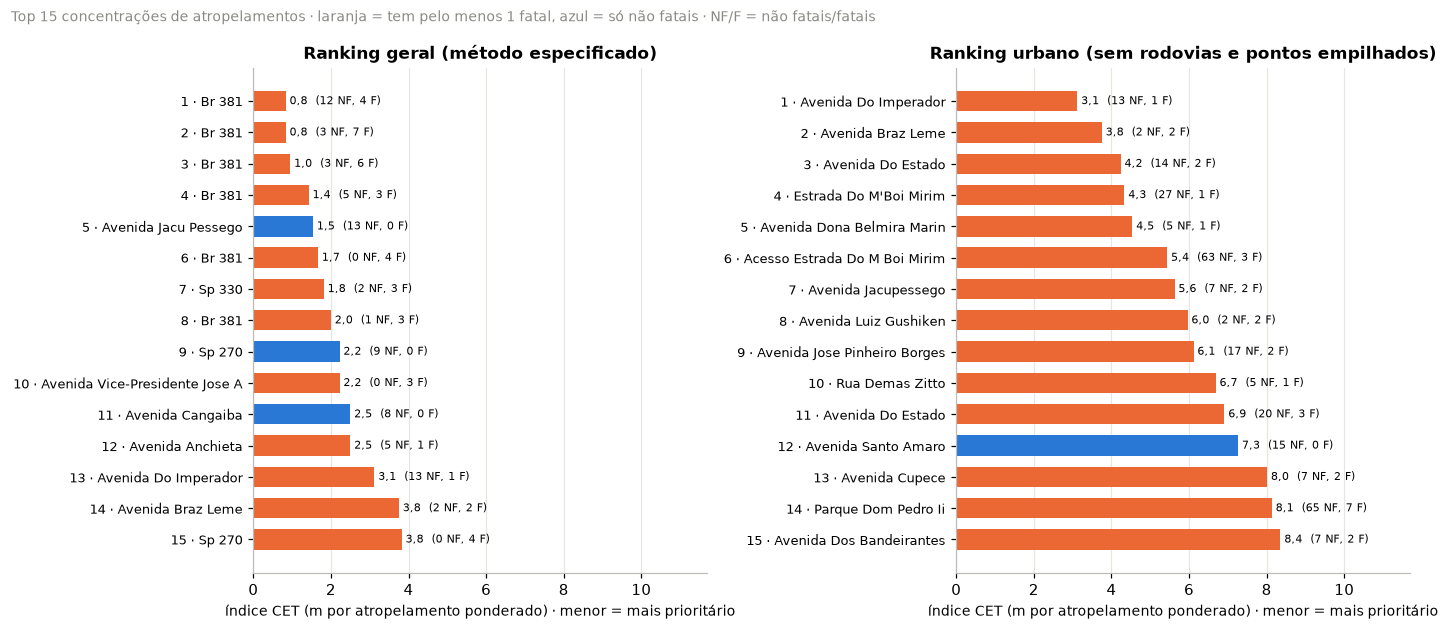

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
paineis = [(grupos.head(15), "rank_prioridade", "Ranking geral (método especificado)"),
           (grupos[elegivel].head(15), "rank_urbano", "Ranking urbano (sem rodovias e pontos empilhados)")]
for ax, (t, col_rank, titulo) in zip(axes, paineis):
    t = t.iloc[::-1]
    ax.barh(np.arange(len(t)), t["indice_cet"], color=np.where(t["n_fatais"] > 0, LARANJA, AZUL), height=0.65)
    ax.set_yticks(np.arange(len(t)))
    ax.set_yticklabels([f"{r} · {v.title()[:30]}" for r, v in zip(t[col_rank], t["via_principal"])], fontsize=8.5)
    for y, (i, nf, f) in enumerate(zip(t["indice_cet"], t["n_nao_fatais"], t["n_fatais"])):
        ax.text(i + 0.1, y, f"{i:.1f}".replace(".", ",") + f"  ({nf} NF, {f} F)", va="center", fontsize=7.5)
    ax.set_xlim(0, grupos[elegivel].head(15)["indice_cet"].max() * 1.4)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("índice CET (m por atropelamento ponderado) · menor = mais prioritário", fontsize=9)
fig.suptitle("Top 15 concentrações de atropelamentos · laranja = tem pelo menos 1 fatal, azul = só não fatais "
             "· NF/F = não fatais/fatais", x=0.01, ha="left", fontsize=9, color=CINZA)
fig.tight_layout()
salvar(fig, "03_top15_indice_cet.png")
plt.show()

**Leitura:** sem rodovias e sem pontos empilhados, o ranking passa a ter cara de lista de intervenção
municipal, com vias de **todas as regiões**: Zona Leste (Av. do Imperador, Jacu Pêssego, José Pinheiro
Borges), Zona Sul (Estrada do M'Boi Mirim, Belmira Marin, Cupecê, Santo Amaro, Bandeirantes) e Centro (Av. do
Estado, Parque Dom Pedro II). Isso bate com o que a CET disse na reunião: "nós temos vias de todas as regiões".

- A **Av. do Estado** aparece duas vezes no top 11 (3º e 11º). O 3º lugar tem 85 m e 14 não fatais + 2
  fatais, um trecho com a mesma escala da "Estado 1" da CET (86 m). O número de casos é diferente (a CET
  contou 3 + 2), então não é possível afirmar que seja o mesmo polígono.
- O **M'Boi Mirim** tem dois grupos no top 6, e o "Acesso Estrada do M'Boi Mirim" (6º) tem o 2º maior peso
  da cidade (72). Ali o problema é volume, não só densidade.
- O **Parque Dom Pedro II / Rangel Pestana** (14º) é o grupo de **maior peso da cidade** (65 não fatais e
  7 fatais). Ele não está mais acima só porque o grupo é longo (~700 m), e a regra do índice divide pela
  extensão.

## 4. O piloto: Av. Celso Garcia, Largo da Concórdia e Av. Rangel Pestana

Procuramos os grupos que têm **pelo menos um atropelamento registrado** nessas vias (comparação sem acento).
A coluna `pontos_na_via` mostra quantos pontos do grupo estão de fato na via buscada, para separar o grupo
"da" via do grupo que só encosta nela num cruzamento.

In [12]:
PILOTO = {"Av. Celso Garcia": "AVENIDA CELSO GARCIA", "Largo da Concórdia": "LARGO DA CONCORDIA",
          "Av. Rangel Pestana": "AVENIDA RANGEL PESTANA"}
# Ponto de referência do piloto: mediana dos atropelamentos registrados no Largo da Concórdia
pts_largo = geo[geo["via_norm"].eq("LARGO DA CONCORDIA")]
LARGO_CONCORDIA = (pts_largo["latitude"].median(), pts_largo["longitude"].median())
print(f"Largo da Concórdia (referência): {LARGO_CONCORDIA[0]:.5f}, {LARGO_CONCORDIA[1]:.5f} "
      f"| {len(pts_largo)} atropelamentos no logradouro")

linhas = []
for nome, via in PILOTO.items():
    na_via = geo[geo["via_norm"].eq(via)]
    for cid, n in na_via.loc[na_via["cluster_id"] >= 0, "cluster_id"].value_counts().items():
        g = grupos.loc[grupos["cluster_id"].eq(cid)].iloc[0]
        linhas.append({"via buscada": nome, "atrop. na via (total)": len(na_via), "cluster_id": cid,
                       "pontos_na_via": n, "rank_prioridade": g["rank_prioridade"], "rank_urbano": g["rank_urbano"],
                       "via_principal": g["via_principal"],
                       "n_nao_fatais": g["n_nao_fatais"], "n_fatais": g["n_fatais"],
                       "extensao_m": round(g["extensao_m"]), "indice_cet": round(g["indice_cet"], 2)})
piloto = pd.DataFrame(linhas).sort_values(["via buscada", "rank_prioridade"])
print(f"de {len(grupos)} grupos no ranking geral e {elegivel.sum()} no ranking urbano")
piloto

Largo da Concórdia (referência): -23.54231, -46.61655 | 14 atropelamentos no logradouro
de 290 grupos no ranking geral e 273 no ranking urbano


,via buscada,atrop. na via (total),cluster_id,pontos_na_via,rank_prioridade,rank_urbano,via_principal,n_nao_fatais,n_fatais,extensao_m,indice_cet
0,Av. Celso Garcia,109,29,29,110,94,AVENIDA CELSO GARCIA,34,2,601,15.03
3,Av. Celso Garcia,109,248,6,131,115,AVENIDA CELSO GARCIA,8,0,126,15.81
1,Av. Celso Garcia,109,223,9,203,186,AVENIDA CELSO GARCIA,9,0,172,19.06
2,Av. Celso Garcia,109,183,6,205,188,AVENIDA CELSO GARCIA,6,2,230,19.14
8,Av. Rangel Pestana,68,17,7,27,14,PARQUE DOM PEDRO II,65,7,699,8.13
6,Av. Rangel Pestana,68,139,21,41,26,AVENIDA RANGEL PESTANA,51,2,591,10.37
5,Av. Rangel Pestana,68,68,26,116,100,AVENIDA RANGEL PESTANA,27,1,461,15.38
7,Av. Rangel Pestana,68,243,8,154,138,AVENIDA RANGEL PESTANA,11,1,236,16.83
9,Av. Rangel Pestana,68,252,1,257,240,RUA FREDERICO ALVARENGA,8,0,175,21.91
4,Largo da Concórdia,14,139,13,41,26,AVENIDA RANGEL PESTANA,51,2,591,10.37


In [13]:
# Grupo mais próximo do ponto de referência do Largo da Concórdia
d_largo = haversine_distances(np.radians([LARGO_CONCORDIA]),
                              np.radians(grupos[["lat_centro", "lon_centro"]].to_numpy()))[0] * R_TERRA
grupos["dist_largo_m"] = d_largo
grupos.nsmallest(3, "dist_largo_m")[["rank_prioridade", "rank_urbano", "cluster_id", "via_principal", "vias", "n_nao_fatais",
                                     "n_fatais", "extensao_m", "indice_cet", "dist_largo_m"]].round(1)

,rank_prioridade,rank_urbano,cluster_id,via_principal,vias,n_nao_fatais,n_fatais,extensao_m,indice_cet,dist_largo_m
40,41,26,139,AVENIDA RANGEL PESTANA,AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | ...,51,2,591.1,10.4,68.7
153,154,138,243,AVENIDA RANGEL PESTANA,AVENIDA RANGEL PESTANA | VIADUTO MAESTRO ALBER...,11,1,235.6,16.8,320.5
115,116,100,68,AVENIDA RANGEL PESTANA,AVENIDA RANGEL PESTANA | RUA CARNEIRO LEAO | R...,27,1,461.5,15.4,777.1


In [14]:
# Onde cai o piloto em relação ao conjunto: percentil do ranking e posição por peso (volume ponderado)
grupos["rank_peso"] = grupos["peso"].rank(ascending=False, method="min").astype(int)
for cid in piloto.drop_duplicates("cluster_id").nsmallest(3, "rank_prioridade")["cluster_id"]:
    g = grupos.loc[grupos["cluster_id"].eq(cid)].iloc[0]
    print(f"cluster {cid:>3} | geral: {g['rank_prioridade']:>3} de {len(grupos)} "
          f"(top {g['rank_prioridade'] / len(grupos):.0%}) | urbano: {g['rank_urbano']:>3} de {elegivel.sum()} "
          f"(top {g['rank_urbano'] / elegivel.sum():.0%}) | por peso: {g['rank_peso']:>3}º ({g['peso']}) | {g['vias']}")

cluster  17 | geral:  27 de 290 (top 9%) | urbano:  14 de 273 (top 5%) | por peso:   1º (86) | PARQUE DOM PEDRO II | PRACA DA SE | AVENIDA RANGEL PESTANA
cluster 139 | geral:  41 de 290 (top 14%) | urbano:  26 de 273 (top 10%) | por peso:   4º (57) | AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | RUA BARAO DE LADARIO
cluster  29 | geral: 110 de 290 (top 38%) | urbano:  94 de 273 (top 34%) | por peso:   7º (40) | AVENIDA CELSO GARCIA | RUA BRESSER | RUA JOSE MONTEIRO


**Leitura (central para o piloto):**

- O **Largo da Concórdia** cai num grupo (cluster 139: Av. Rangel Pestana + Largo da Concórdia + R. Barão de
  Ladário) cujo centro fica a **~70 m** do ponto de referência do Largo. Esse grupo está em **26º de 273 no
  ranking urbano (top 10%)** e em 41º de 290 no geral. É o **4º maior peso da cidade**: 51 não fatais e 2
  fatais em ~590 m.
- O grupo vizinho, **Parque Dom Pedro II / Praça da Sé / Rangel Pestana**, é o **14º urbano (top 5%) e o de
  maior peso da cidade**. Rangel Pestana e Largo da Concórdia formam um único **corredor** Centro → Brás com
  dois grupos no top 30 urbano.
- A **Av. Celso Garcia em si** (cluster 29, trecho da R. Bresser) fica em **94º urbano (top 34%)**, mas é o
  **7º maior peso**. Ela tem muitos atropelamentos espalhados por ~600 m, por isso a densidade é menor. É o
  que o técnico da CET disse na reunião: "na medida que você vai indo para a Zona Leste, você vai percebendo
  que a concentração vai diminuindo. Sim, no Largo da Concórdia já é clássico isso."

**Conclusão para o projeto:** o dado sustenta o piloto **no nó do Largo da Concórdia** (início da Celso
Garcia, encontro com a Rangel Pestana), e não num ponto qualquer ao longo da Celso Garcia. Ali o local está
entre os 10% mais prioritários pelo índice e entre os 4 maiores em volume ponderado. A ressalva honesta: pelo
índice puro, há ~25 trechos urbanos mais densos. A escolha do piloto se apoia na **combinação de densidade
alta com volume muito alto**, no fluxo de pedestres (estação Brás, comércio, ônibus) e no fato de a própria
CET tratar o local como concentração conhecida ("Celso Garcia II").

## 5. Comparação com o ranking da CET

**Fonte tentada:** o PDF *Reunião Câmara Temática da Mobilidade a Pé, 11/03/2026* no site da Prefeitura.
O download funcionou, mas o arquivo é a **transcrição** da reunião (34 páginas de texto, com o cabeçalho da
Prefeitura como única imagem). A tabela com as 244 concentrações aparecia nos **slides**, que não estão no
PDF. Por isso a comparação completa (pares a menos de 150 m, sobreposição no top 20 e no top 50, Spearman)
fica **pendente**, com a função pronta logo abaixo.

O que a transcrição permite verificar:

| Concentração citada (CET) | O que foi dito |
|---|---|
| (1º, não nomeado na fala) | "o primeiro seria esse" (apontando para o slide) |
| Tiradentes 1 | 2º do ranking |
| Estado 2 | 3º do ranking |
| São João 1 | 4º do ranking |
| Estado 1 | 86 m, 3 não fatais + 2 fatais, índice ≈ 9,6 (posição não dita) |
| Interlagos II e III | índice ≈ 5 na Interlagos III (posição não dita) |
| Celso Garcia II | perto do Templo de Salomão (Brás); posição não dita |
| Armando de Arruda Pereira | exemplo de concentração delimitada |

In [15]:
CET_CITADAS = {  # concentração citada na reunião → padrão do nome da via na base (sem acento)
    "Tiradentes 1 (2º CET)": r"^AVENIDA TIRADENTES$",
    "Estado 1 / Estado 2 (3º CET)": r"AV(?:ENIDA)? DO ESTADO",
    "São João 1 (4º CET)": r"^AVENIDA SAO JOAO$",
    "Interlagos II / III": r"^AVENIDA INTERLAGOS$",
    "Celso Garcia II": r"^AVENIDA CELSO GARCIA$",
    "Armando de Arruda Pereira": r"ARMANDO DE ARRUDA PEREIRA",
}
linhas = []
for nome, via in CET_CITADAS.items():
    na_via = geo["via_norm"].str.contains(via, regex=True, na=False)
    ids = geo.loc[na_via & (geo["cluster_id"] >= 0), "cluster_id"].unique()
    g = grupos[grupos["cluster_id"].isin(ids)]
    linhas.append({"concentração CET": nome, "via": via, "atrop. na via": int(na_via.sum()),
                   "grupos DBSCAN que tocam a via": len(g),
                   "melhor rank DBSCAN": g["rank_prioridade"].min() if len(g) else None,
                   "melhor rank urbano": g["rank_urbano"].min() if len(g) else None,
                   "grupos no top 30 urbano": int((g["rank_urbano"] <= 30).sum())})
pd.DataFrame(linhas)

,concentração CET,via,atrop. na via,grupos DBSCAN que tocam a via,melhor rank DBSCAN,melhor rank urbano,grupos no top 30 urbano
0,Tiradentes 1 (2º CET),^AVENIDA TIRADENTES$,37,4,36,22,1
1,Estado 1 / Estado 2 (3º CET),AV(?:ENIDA)? DO ESTADO,113,15,16,3,3
2,São João 1 (4º CET),^AVENIDA SAO JOAO$,5,3,35,21,1
3,Interlagos II / III,^AVENIDA INTERLAGOS$,85,4,79,63,0
4,Celso Garcia II,^AVENIDA CELSO GARCIA$,109,4,110,94,0
5,Armando de Arruda Pereira,ARMANDO DE ARRUDA PEREIRA,76,6,43,28,1


**Leitura (comparação parcial):** as três vias que a CET citou no topo do seu ranking (**Tiradentes,
Estado, São João**) têm grupos no **top 30 urbano** do DBSCAN. A Av. do Estado chega a 3º lugar, com 3
grupos no top 30. Ou seja, o método automático encontra **as mesmas vias** entre as prioridades. **As
posições não coincidem**: a CET põe Tiradentes 1 em 2º e São João 1 em 4º, e aqui elas ficam em 22º e 21º.
Isso é esperado porque (1) a extensão aqui é o diâmetro do grupo, não o trecho medido na via; (2) a CET pode
ter recortado polígonos menores, o que reduz a extensão e o índice; (3) as bases diferem em ~800 registros.
A Celso Garcia (94º) e a Interlagos (63º) ficam mais abaixo. A comparação quantitativa (Spearman, top 20/50)
só é possível com a lista completa: ver PENDENTE abaixo.

### 5.1 Função de comparação completa

`comparar_com_cet` recebe a lista da CET com **nome, posição no ranking e coordenadas** (lat/lon do centro de
cada concentração) e calcula:

1. **pareamento:** para cada concentração da CET, o grupo do DBSCAN mais próximo e se ele fica a menos de
   150 m;
2. **sobreposição no top 20 e no top 50:** das concentrações da CET no top N, quantas têm par no top N do
   DBSCAN;
3. **Spearman** entre a posição na CET e a posição no DBSCAN, só entre os pares.

Antes de usar com a lista real, testamos a função com uma "CET falsa", feita a partir dos nossos próprios grupos
com a ordem invertida. O pareamento tem que dar 100% e o Spearman tem que dar −1.

In [16]:
def comparar_com_cet(cet: pd.DataFrame, grupos: pd.DataFrame, raio_m: float = 150) -> dict:
    """cet: colunas nome, rank_cet, lat, lon. grupos: saída deste notebook."""
    d = haversine_distances(np.radians(cet[["lat", "lon"]].to_numpy()),
                            np.radians(grupos[["lat_centro", "lon_centro"]].to_numpy())) * R_TERRA
    j = d.argmin(axis=1)
    pares = cet.assign(cluster_id=grupos["cluster_id"].to_numpy()[j],
                       rank_dbscan=grupos["rank_prioridade"].to_numpy()[j],
                       dist_m=d[np.arange(len(cet)), j].round(1))
    pares["pareado"] = pares["dist_m"] < raio_m
    ok = pares[pares["pareado"]]
    sobre = {n: int(((ok["rank_cet"] <= n) & (ok["rank_dbscan"] <= n)).sum()) for n in (20, 50)}
    rho = spearmanr(ok["rank_cet"], ok["rank_dbscan"]).statistic if len(ok) > 2 else np.nan
    return {"pares": pares, "% pareadas": pares["pareado"].mean() * 100,
            "top20 em comum": sobre[20], "top50 em comum": sobre[50], "spearman": rho}

# Teste de sanidade: "CET falsa" = nossos 60 primeiros grupos com o ranking invertido
falsa = grupos.head(60).rename(columns={"lat_centro": "lat", "lon_centro": "lon"})
falsa = falsa.assign(nome=falsa["via_principal"], rank_cet=falsa["rank_prioridade"].max() + 1 - falsa["rank_prioridade"])
teste = comparar_com_cet(falsa[["nome", "rank_cet", "lat", "lon"]], grupos)
assert teste["% pareadas"] == 100 and np.isclose(teste["spearman"], -1), "função de comparação com defeito"
print(f"teste OK: {teste['% pareadas']:.0f}% pareadas, Spearman = {teste['spearman']:.2f}")

teste OK: 100% pareadas, Spearman = -1.00


> **PENDENTE: lista da CET.** Para fechar esta seção é preciso a tabela das 244 concentrações (ou pelo menos as
> 30 priorizadas) com nome, posição e localização. Caminhos: pedir os slides da apresentação à GST/CET
> (Marcelo Espel) ou à secretaria da Câmara Temática, ou procurar a nota técnica quando for publicada.
> Com a lista em `data/processed/cet_concentracoes.csv` (colunas `nome;rank_cet;lat;lon`), a célula abaixo
> roda a comparação sozinha. Se os rankings saírem diferentes, isso também é resultado: deve ser documentado,
> e não forçado a coincidir.

In [17]:
CET_CSV = PROCESSED / "cet_concentracoes.csv"
if CET_CSV.exists():
    cet = pd.read_csv(CET_CSV, sep=";", decimal=",")
    res = comparar_com_cet(cet, grupos)
    print({k: v for k, v in res.items() if k != "pares"})
    display(res["pares"].sort_values("rank_cet").head(30))
else:
    print(f"PENDENTE: {CET_CSV.relative_to(ROOT)} não encontrado; comparação completa não executada.")

PENDENTE: data\processed\cet_concentracoes.csv não encontrado; comparação completa não executada.


## 6. Mapas

### 6.1 Mapa interativo (folium)

Os 50 primeiros do ranking aparecem como círculos com **raio proporcional ao peso** e **cor pelo índice**
(laranja = índice baixo = mais prioritário; azul = índice mais alto). O popup traz os dois ranks, via principal,
fatais, não fatais, extensão e índice. O Largo da Concórdia tem um marcador próprio.

O mapa tem **duas camadas**, que se alternam no controle do canto superior direito: o **top 50 urbano**
(ligado ao abrir, é o que serve para decidir a intervenção) e o **top 50 geral** (desligado, mostra os
grupos de rodovia e de pontos empilhados da seção 3.2).

In [18]:
top50 = grupos[elegivel].head(50).copy()      # top 50 urbano
top50_geral = grupos.head(50).copy()
cmap = bcm.LinearColormap([LARANJA, "#f2c3a8", AZUL], vmin=0, vmax=top50["indice_cet"].max(),
                          caption="Índice CET (m por atropelamento ponderado) · menor = mais prioritário")
mapa = folium.Map(location=[-23.58, -46.62], zoom_start=11, tiles="OpenStreetMap")

def desenhar(tab, camada, col_rank):
    for _, g in tab.iloc[::-1].iterrows():  # desenha do menos para o mais prioritário (o 1º fica por cima)
        ru = "fora (rodovia/empilhado)" if pd.isna(g.rank_urbano) else f"#{g.rank_urbano}"
        popup = (f"<b>{g.via_principal.title()}</b><br>rank urbano: {ru} · rank geral: #{g.rank_prioridade}<br>"
                 f"vias: {g.vias.title()}<br>fatais: {g.n_fatais} · não fatais: {g.n_nao_fatais} · peso: {g.peso}<br>"
                 f"extensão: {g.extensao_m:.0f} m · índice: {g.indice_cet:.2f}")
        folium.CircleMarker([g.lat_centro, g.lon_centro], radius=4 + 1.6 * np.sqrt(g.peso),
                            color=cmap(min(g.indice_cet, cmap.vmax)), weight=1.5, fill=True, fill_opacity=0.65,
                            popup=folium.Popup(popup, max_width=340),
                            tooltip=f"#{g[col_rank]} {g.via_principal.title()}").add_to(camada)

camada_u = folium.FeatureGroup(name="Top 50 urbano (rank_urbano)", show=True)
camada_g = folium.FeatureGroup(name="Top 50 geral (rank_prioridade)", show=False)
desenhar(top50, camada_u, "rank_urbano")
desenhar(top50_geral, camada_g, "rank_prioridade")
camada_u.add_to(mapa); camada_g.add_to(mapa)
folium.Marker(LARGO_CONCORDIA, tooltip="Piloto: Largo da Concórdia (Brás)",
              popup="<b>Piloto do projeto</b><br>Largo da Concórdia / Av. Celso Garcia",
              icon=folium.Icon(color="black", icon="star")).add_to(mapa)
cmap.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(EVID / "mapa_pontos_criticos.html")
print("salvo:", (EVID / "mapa_pontos_criticos.html").relative_to(ROOT))
mapa

salvo: docs\evidencias\estudo_b\mapa_pontos_criticos.html


### 6.2 Mapa estático (para o PDF)

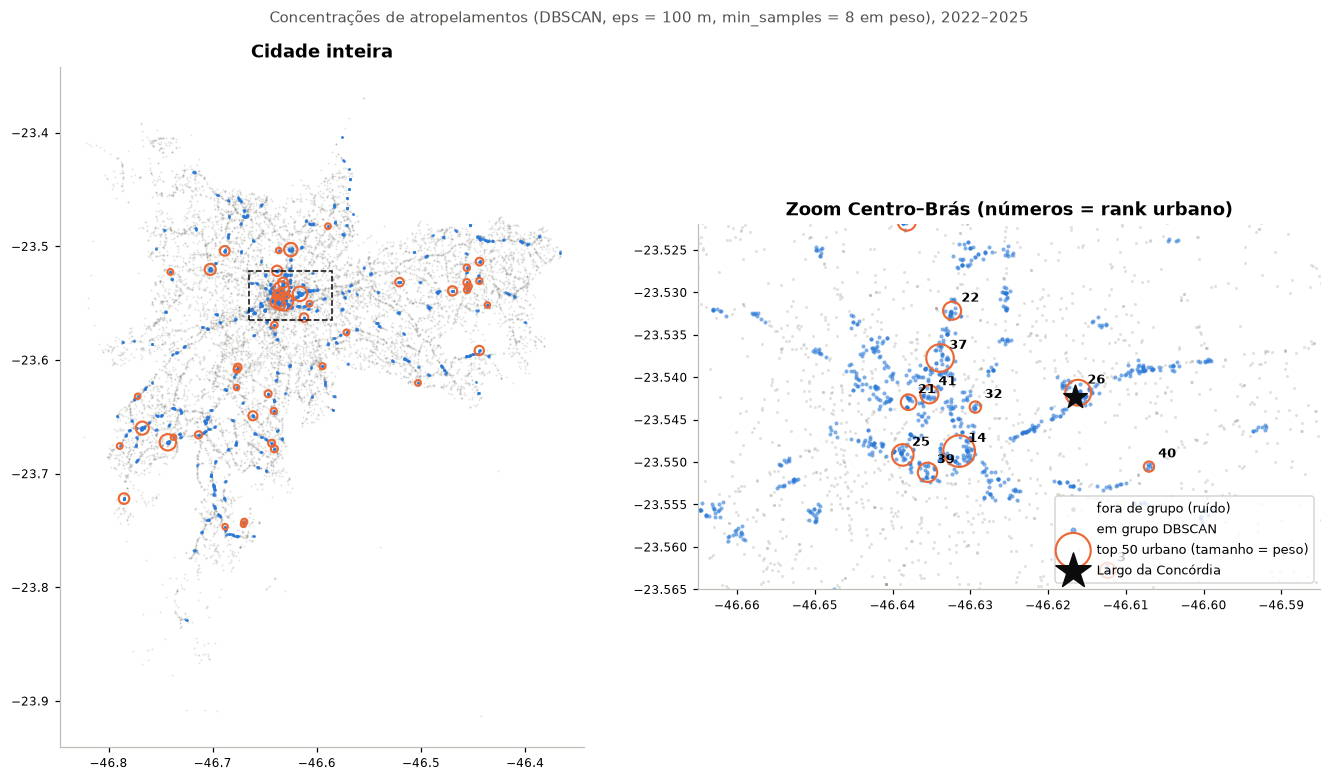

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 7.2), gridspec_kw={"width_ratios": [1, 1.05]})
CENTRO = dict(lon=(-46.665, -46.585), lat=(-23.565, -23.522))
ruido, agrup = geo[geo["cluster_id"] < 0], geo[geo["cluster_id"] >= 0]
for k, ax in enumerate(axes):
    zoom = k == 1
    ax.scatter(ruido["longitude"], ruido["latitude"], s=4 if zoom else 1.5, color=CINZA, alpha=0.25, linewidths=0,
               label="fora de grupo (ruído)")
    ax.scatter(agrup["longitude"], agrup["latitude"], s=7 if zoom else 2.5, color=AZUL, alpha=0.6, linewidths=0,
               label="em grupo DBSCAN")
    ax.scatter(top50["lon_centro"], top50["lat_centro"], s=(top50["peso"] * (5 if zoom else 1.6)),
               facecolors="none", edgecolors=LARANJA, linewidths=1.4, label="top 50 urbano (tamanho = peso)")
    if zoom:
        for _, g in top50.iterrows():
            if CENTRO["lon"][0] < g.lon_centro < CENTRO["lon"][1] and CENTRO["lat"][0] < g.lat_centro < CENTRO["lat"][1]:
                ax.annotate(str(g.rank_urbano), (g.lon_centro, g.lat_centro), fontsize=8.5, fontweight="bold",
                            xytext=(6, 6), textcoords="offset points")
        ax.scatter(*LARGO_CONCORDIA[::-1], marker="*", s=260, color="#0b0b0b", zorder=5, label="Largo da Concórdia")
    ax.set_aspect(1 / np.cos(np.radians(-23.6)))
    ax.grid(False); ax.tick_params(labelsize=8)
axes[0].add_patch(plt.Rectangle((CENTRO["lon"][0], CENTRO["lat"][0]), np.diff(CENTRO["lon"])[0],
                                np.diff(CENTRO["lat"])[0], fill=False, ec="#0b0b0b", lw=1, ls="--"))
axes[0].set_title("Cidade inteira")
axes[1].set_xlim(CENTRO["lon"]); axes[1].set_ylim(CENTRO["lat"])
axes[1].set_title("Zoom Centro–Brás (números = rank urbano)")
axes[1].legend(loc="lower right", markerscale=1.5, frameon=True, fontsize=8.5)
fig.suptitle(f"Concentrações de atropelamentos (DBSCAN, eps = {EPS_M} m, min_samples = {MIN_SAMPLES} em peso), "
             "2022–2025", fontsize=10, color="#52514e")
fig.tight_layout()
salvar(fig, "03_mapa_grupos_dbscan.png")
plt.show()

## 7. Banco SQLite do projeto

Banco: `data/processed/seguranca_viaria.db`. As tabelas são criadas com `CREATE TABLE` explícito, com chaves
primárias, chaves estrangeiras e `CHECK` nos campos de categoria, para que a central e o ESP32 não consigam
gravar valores fora do combinado. O mesmo esquema está em `src/central/schema.sql`.

- **`sinistros`**: os 16.245 atropelamentos do recorte, **inclusive os sem coordenada** (lat/lon nulas). A
  coluna extra `coord_valida` mostra por que um registro não tem `cluster_id`;
- **`clusters`**: os grupos com métricas, os dois rankings (`rank_prioridade` geral e `rank_urbano`), as
  colunas de diagnóstico da seção 3.2 e os hiperparâmetros que os geraram (`eps_m`,
  `min_samples`, `criado_em`). Assim fica rastreável qual rodada produziu cada ranking;
- **`eventos`** e **`alertas`**: **só criadas, vazias**. Vão ser preenchidas pela visão computacional, pelo
  ESP32 e pela central (dias 14 a 17).

O banco é recriado do zero a cada execução, para o resultado não depender de rodadas anteriores. O `.db`
não vai para o Git (está no `.gitignore`): ele é gerado de novo rodando este notebook.

In [20]:
DDL = """
CREATE TABLE clusters (
    cluster_id      INTEGER PRIMARY KEY,
    lat_centro      REAL    NOT NULL,
    lon_centro      REAL    NOT NULL,
    n_fatais        INTEGER NOT NULL,
    n_nao_fatais    INTEGER NOT NULL,
    peso            INTEGER NOT NULL,             -- n_nao_fatais + 3 * n_fatais
    extensao_m      REAL    NOT NULL,             -- maior distância entre 2 pontos do grupo (aproximação)
    indice_cet      REAL    NOT NULL,             -- max(extensao_m, 20) / peso; menor = mais prioritário
    rank_prioridade INTEGER NOT NULL UNIQUE,      -- ranking geral (todos os grupos)
    rank_urbano     INTEGER UNIQUE,               -- nulo = rodovia ou pontos empilhados (seção 3.2)
    n_coords_distintas INTEGER NOT NULL,
    pct_via_urbana  REAL    NOT NULL,
    via_principal   TEXT,
    eps_m           REAL    NOT NULL,
    min_samples     INTEGER NOT NULL,
    criado_em       TEXT    NOT NULL
);
CREATE TABLE sinistros (
    id_sinistro   INTEGER PRIMARY KEY,
    data_sinistro TEXT    NOT NULL,               -- AAAA-MM-DD
    hora          INTEGER,                        -- 0-23; nulo se não informado
    latitude      REAL,
    longitude     REAL,
    coord_valida  INTEGER NOT NULL CHECK (coord_valida IN (0, 1)),
    fatal         INTEGER NOT NULL CHECK (fatal IN (0, 1)),
    tipo_via      TEXT,
    logradouro    TEXT,
    cluster_id    INTEGER REFERENCES clusters(cluster_id)   -- nulo = ruído ou sem coordenada
);
CREATE INDEX idx_sinistros_cluster ON sinistros(cluster_id);
CREATE TABLE eventos (
    id           INTEGER PRIMARY KEY AUTOINCREMENT,
    timestamp    TEXT    NOT NULL,
    origem       TEXT    NOT NULL CHECK (origem IN ('yolo', 'esp32', 'central')),
    cluster_id   INTEGER REFERENCES clusters(cluster_id),
    tipo         TEXT    NOT NULL,
    valor        REAL,
    payload_json TEXT
);
CREATE TABLE alertas (
    id         INTEGER PRIMARY KEY AUTOINCREMENT,
    timestamp  TEXT    NOT NULL,
    cluster_id INTEGER REFERENCES clusters(cluster_id),
    modo       TEXT    NOT NULL CHECK (modo IN ('normal', 'pedestre', 'escola', 'chuva', 'ambulancia')),
    motivo     TEXT,
    risco      REAL,
    enviado    INTEGER NOT NULL DEFAULT 0 CHECK (enviado IN (0, 1))
);
"""

assert atrop["id_sinistro"].str.fullmatch(r"\d+").all() and atrop["id_sinistro"].is_unique
criado_em = dt.datetime.now().isoformat(timespec="seconds")

tab_clusters = grupos.assign(eps_m=float(EPS_M), min_samples=MIN_SAMPLES, criado_em=criado_em)[
    ["cluster_id", "lat_centro", "lon_centro", "n_fatais", "n_nao_fatais", "peso", "extensao_m", "indice_cet",
     "rank_prioridade", "rank_urbano", "n_coords_distintas", "pct_via_urbana", "via_principal", "eps_m",
     "min_samples", "criado_em"]]
tab_clusters["rank_urbano"] = tab_clusters["rank_urbano"].astype(object).where(tab_clusters["rank_urbano"].notna(), None)

s = atrop.merge(geo[["id_sinistro", "cluster_id"]], on="id_sinistro", how="left")
cid = s["cluster_id"].where(s["cluster_id"] >= 0)
tab_sinistros = pd.DataFrame({
    "id_sinistro": s["id_sinistro"].astype("int64"),
    "data_sinistro": s["data_sinistro"].dt.strftime("%Y-%m-%d"),
    "hora": s["hora"].astype(object).where(s["hora"].notna(), None),
    "latitude": s["latitude"].where(s["coord_valida"]),
    "longitude": s["longitude"].where(s["coord_valida"]),
    "coord_valida": s["coord_valida"].astype(int),
    "fatal": s["fatal"].astype(int),
    "tipo_via": s["tipo_via"],
    "logradouro": s["logradouro_pad"],
    "cluster_id": cid.astype(object).where(cid.notna(), None),
})

DB_PATH.unlink(missing_ok=True)
with sqlite3.connect(DB_PATH) as con:
    con.execute("PRAGMA foreign_keys = ON")
    con.executescript(DDL)
    tab_clusters.to_sql("clusters", con, if_exists="append", index=False)
    tab_sinistros.to_sql("sinistros", con, if_exists="append", index=False)
print(f"banco gravado: {DB_PATH.relative_to(ROOT)} ({DB_PATH.stat().st_size / 1e6:.1f} MB)")

banco gravado: data\processed\seguranca_viaria.db (1.7 MB)


### 7.1 Consultas de checagem

In [21]:
con = sqlite3.connect(DB_PATH)
q = lambda sql: pd.read_sql_query(sql, con)
print(q("SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name")
      ["name"].tolist())
q("""
SELECT 'sinistros' AS tabela, COUNT(*) AS linhas FROM sinistros
UNION ALL SELECT 'sinistros com cluster', COUNT(*) FROM sinistros WHERE cluster_id IS NOT NULL
UNION ALL SELECT 'sinistros sem coordenada válida', COUNT(*) FROM sinistros WHERE coord_valida = 0
UNION ALL SELECT 'clusters', COUNT(*) FROM clusters
UNION ALL SELECT 'eventos', COUNT(*) FROM eventos
UNION ALL SELECT 'alertas', COUNT(*) FROM alertas
""")

['alertas', 'clusters', 'eventos', 'sinistros']


,tabela,linhas
0,sinistros,16245
1,sinistros com cluster,3163
2,sinistros sem coordenada válida,650
3,clusters,290
4,eventos,0
5,alertas,0


In [22]:
q("""
SELECT c.rank_prioridade, c.cluster_id, c.via_principal, c.n_nao_fatais, c.n_fatais, c.peso,
       ROUND(c.extensao_m) AS extensao_m, ROUND(c.indice_cet, 2) AS indice_cet,
       COUNT(s.id_sinistro) AS sinistros_ligados
FROM clusters c LEFT JOIN sinistros s ON s.cluster_id = c.cluster_id
GROUP BY c.cluster_id
ORDER BY c.rank_prioridade
LIMIT 10
""")

,rank_prioridade,cluster_id,via_principal,n_nao_fatais,n_fatais,peso,extensao_m,indice_cet,sinistros_ligados
0,1,57,BR 381,12,4,24,5.0,0.83,16
1,2,81,BR 381,3,7,24,5.0,0.83,10
2,3,90,BR 381,3,6,21,5.0,0.95,9
3,4,130,BR 381,5,3,14,5.0,1.43,8
4,5,55,AVENIDA JACU PESSEGO,13,0,13,15.0,1.54,13
5,6,250,BR 381,0,4,12,5.0,1.67,4
6,7,194,SP 330,2,3,11,5.0,1.82,5
7,8,16,BR 381,1,3,10,5.0,2.00,4
8,9,140,SP 270,9,0,9,0.0,2.22,9
9,10,249,AVENIDA VICE-PRESIDENTE JOSE ALENCAR GOMES DA ...,0,3,9,2.0,2.22,3


In [23]:
q("""
SELECT rank_urbano, rank_prioridade, cluster_id, via_principal, n_nao_fatais, n_fatais,
       ROUND(extensao_m) AS extensao_m, ROUND(indice_cet, 2) AS indice_cet
FROM clusters WHERE rank_urbano IS NOT NULL
ORDER BY rank_urbano
LIMIT 10
""")

,rank_urbano,rank_prioridade,cluster_id,via_principal,n_nao_fatais,n_fatais,extensao_m,indice_cet
0,1,13,48,AVENIDA DO IMPERADOR,13,1,50.0,3.12
1,2,14,267,AVENIDA BRAZ LEME,2,2,30.0,3.75
2,3,16,225,AVENIDA DO ESTADO,14,2,85.0,4.24
3,4,17,212,ESTRADA DO M'BOI MIRIM,27,1,130.0,4.34
4,5,18,163,AVENIDA DONA BELMIRA MARIN,5,1,36.0,4.54
5,6,19,32,ACESSO ESTRADA DO M BOI MIRIM,63,3,391.0,5.44
6,7,20,87,AVENIDA JACUPESSEGO,7,2,73.0,5.63
7,8,21,284,AVENIDA LUIZ GUSHIKEN,2,2,48.0,5.96
8,9,22,120,AVENIDA JOSE PINHEIRO BORGES,17,2,141.0,6.11
9,10,23,56,RUA DEMAS ZITTO,5,1,53.0,6.68


In [24]:
# Integridade: os totais do banco batem com o DataFrame?
chk = q("SELECT SUM(n_nao_fatais + n_fatais) AS em_clusters, SUM(peso) AS peso FROM clusters").iloc[0]
assert chk["em_clusters"] == (geo["cluster_id"] >= 0).sum() == q("SELECT COUNT(*) n FROM sinistros WHERE cluster_id IS NOT NULL")["n"][0]
assert q("PRAGMA foreign_key_check").empty
con.close()
print("checagens OK: totais por cluster = sinistros ligados; nenhuma chave estrangeira órfã")

checagens OK: totais por cluster = sinistros ligados; nenhuma chave estrangeira órfã


## 8. Evidências para o PDF e o vídeo

Ficam em `docs/evidencias/estudo_b/`: os PNGs deste notebook (já salvos acima), o mapa interativo, a tabela
`ranking_top50.csv` (ranking geral), a `ranking_urbano_top50.csv` e os gráficos dos notebooks 01 e 02. Os gráficos do 01 e do 02 são **extraídos das saídas
já renderizadas** nos `.ipynb`, sem rodar a análise de novo. Cada arquivo recebe o nome da seção do notebook
de onde saiu.

In [25]:
cols_csv = ["rank_prioridade", "rank_urbano", "cluster_id", "via_principal", "vias", "n_nao_fatais", "n_fatais",
            "peso", "extensao_m", "n_coords_distintas", "pct_via_urbana", "indice_cet", "lat_centro", "lon_centro"]
arred = {"extensao_m": 1, "indice_cet": 3, "pct_via_urbana": 2, "lat_centro": 6, "lon_centro": 6}
grupos.head(50)[cols_csv].round(arred).to_csv(EVID / "ranking_top50.csv", sep=";", decimal=",", index=False,
                                              encoding="utf-8-sig")
grupos[elegivel].head(50)[cols_csv].round(arred).to_csv(EVID / "ranking_urbano_top50.csv", sep=";", decimal=",",
                                                        index=False, encoding="utf-8-sig")

def slug(t: str) -> str:
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode().lower()
    return "_".join("".join(c if c.isalnum() else " " for c in t).split())[:50]

extraidas = []
for nb_nome, prefixo in [("01_limpeza_analise_atropelamentos_sp.ipynb", "01"),
                         ("02_modelo_letalidade_atropelamentos_sp.ipynb", "02")]:
    nb = json.loads((NOTEBOOKS / nb_nome).read_text(encoding="utf-8"))
    secao, n = "inicio", 0
    for c in nb["cells"]:
        if c["cell_type"] == "markdown":
            titulos = [l.lstrip("#").strip() for l in "".join(c["source"]).splitlines() if l.startswith("#")]
            if titulos:
                secao = titulos[-1]
        for o in c.get("outputs", []):
            png = o.get("data", {}).get("image/png")
            if png:
                n += 1
                arq = EVID / f"{prefixo}_{n:02d}_{slug(secao)}.png"
                arq.write_bytes(base64.b64decode(png))
                extraidas.append(arq.name)
print(f"{len(extraidas)} gráficos extraídos dos notebooks 01 e 02")
pd.DataFrame({"arquivo": sorted(p.name for p in EVID.iterdir()),
              "KB": [round(p.stat().st_size / 1024) for p in sorted(EVID.iterdir())]})

7 gráficos extraídos dos notebooks 01 e 02


,arquivo,KB
0,01_01_5_1_evolucao_anual.png,38
1,01_02_5_2_quando_acontecem_hora_do_dia_dia_da_...,28
2,01_03_5_3_quem_e_atropelado_idade_das_vitimas_...,35
3,01_04_5_5_onde_acontecem_vias_com_mais_atropel...,75
4,01_05_5_6_pontos_criticos_grade_de_500_m.png,248
5,02_01_2_modelo_de_regressao_logistica.png,68
6,02_02_3_probabilidades_previstas_traduzindo_pa...,54
7,03_grade_hiperparametros.png,101
8,03_mapa_grupos_dbscan.png,303
9,03_top15_indice_cet.png,153


## 9. Limitações

- **A extensão é aproximada.** `extensao_m` é o maior diâmetro do grupo (a maior distância entre dois pontos),
  e não o comprimento do trecho medido sobre a via, como fez a CET. Em grupos que pegam um cruzamento ou uma
  praça, o diâmetro pode ser maior que o trecho de uma via só. Isso aumenta o índice e empurra esses grupos
  para baixo no ranking. O piso de 20 m resolve o caso oposto (pontos empilhados na mesma coordenada).
- **Cerca de 4% dos atropelamentos ficam de fora** por falta de coordenada válida (vazia, zerada ou fora do
  município). Se a falta de coordenada for mais comum em certos lugares (por exemplo, registros vindos de outra
  fonte, sem o boletim completo), esses lugares ficam sub-representados.
- **O DBSCAN é sensível ao `eps`.** A seção 2.1 mostra que, de 100 para 150 m, o número de grupos e o tamanho
  do maior grupo mudam muito. A escolha de 100 m é uma decisão justificada, mas não é a única possível. O
  ranking de um grupo específico pode mudar com outro `eps`, por isso a posição do piloto deve ser lida
  junto com essa sensibilidade.
- **As notificações (`NOTIFICACAO`) estão excluídas**, como no painel do Infosiga e nos notebooks 01 e 02.
  Isso explica parte da diferença para os 16.390 registros da CET.
- **Comparação com a CET pendente.** Sem a tabela das 244 concentrações, só foi possível conferir as vias
  citadas na reunião (seção 5). A função de comparação completa está pronta e testada.
- **Pontos empilhados e rodovias dominam o ranking geral.** Registros geocodificados num ponto padrão (km da
  rodovia, centro da rua) produzem grupos de extensão ~0 e índice artificialmente baixo, e o piso de 20 m não
  basta para corrigir isso. O `rank_urbano` tira esses grupos, mas o critério (≤ 2 coordenadas distintas,
  maioria em rodovia) é uma decisão nossa, não da CET.
- **Peso 3 para fatal** é uma convenção da CET, não um valor estimado. Ela é mantida aqui para o resultado ser
  comparável com o da CET.